# 4 · Modeling — Binôme A: DeepLabV3+ with transfer learning

**CRISP-DM phase 4 (Modeling).** Team: Ines Trabelsi & Emna (FR, Binôme A). Previous: [`../3_Data_Preparation.ipynb`](../3_Data_Preparation.ipynb) · Next: [`../5_Evaluation.ipynb`](../5_Evaluation.ipynb)

Supervised binary segmentation of road anomalies: a **ResNet50 encoder pretrained on ImageNet** (frozen), an **ASPP** module and a **decoder** trained on RoadAnomaly. The model is defined in `src/roadanomaly/models/deeplabv3plus.py`.

**Protocol.** The checkpoint is chosen by the minimum validation loss, then the threshold by the per-image mean F1 on validation. This notebook never loads the test split: the single test evaluation is in notebook 5 and the explanations (Seg-Grad-CAM, deletion / insertion) in notebook 6.

**Provenance.** This notebook reproduces Ines's experiment `20261101T012507Z-f4ec27a0` with the same settings (batch 2, Adam 1e-3, binary cross-entropy, at most 20 epochs, patience 5, 51 threshold quantiles). Her original run (Windows, CPU, TensorFlow 2.21) is kept with its outputs in `archive/A_deeplabv3plus_original_run_ines.ipynb`: validation F1 0.680, AP 0.767, AUROC 0.940. The run below uses the team's reference environment (Linux, TensorFlow 2.20, GPU, deterministic ops), so its numbers differ slightly; the numbers reported for the group are those of this run.

## 0. Setup

In [1]:
# Import libraries
import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")   # hide TensorFlow C++ log lines (e.g. the harmless "use_unbounded_threadpool" notice)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import keras
import tensorflow as tf
tf.get_logger().setLevel("ERROR")                    # hide tf.function retracing notices

from roadanomaly import data_pipeline as dp, evaluation, postprocessing as pp
from roadanomaly.gpu import setup_gpu
from roadanomaly.inference import save_artifact
from roadanomaly.models.deeplabv3plus import build_deeplabv3plus
from roadanomaly.protocol import IMG_SIZE, MIN_OBJECT_PX, SEED

import warnings
warnings.filterwarnings('ignore')

In [2]:
# Hyper-parameters of Ines's experiment
BATCH_SIZE = 2
LEARNING_RATE = 1e-3
MAX_EPOCHS = 20
PATIENCE = 5                                        # early stopping on the validation loss
DECODER_CHANNELS = 128
THRESHOLD_QUANTILES = np.linspace(0.01, 0.99, 51)   # candidate thresholds on the validation probabilities

FIG_DIR = dp.FIG_DIR
CHECKPOINT = dp.REPO_ROOT / "checkpoints" / "A_deeplabv3plus" / "best.keras"   # git-ignored
CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()
GPU_NAME = setup_gpu()
print("TensorFlow:", tf.__version__, "| GPU:", GPU_NAME)

GPU: NVIDIA GeForce RTX 4060 Laptop GPU | compute capability: (8, 9)
TensorFlow: 2.20.0 | GPU: NVIDIA GeForce RTX 4060 Laptop GPU


## 1. Load and check the data
Images and masks come from the shared loader; masks are resized with nearest neighbour so they stay binary. Anomaly pixels are about 10 % of the images: the classes are imbalanced.

In [3]:
train_frames, x_train, y_train = dp.load_split("train", IMG_SIZE)
val_frames, x_val, y_val = dp.load_split("val", IMG_SIZE)
assert len(train_frames) == 42 and len(val_frames) == 9 and set(train_frames).isdisjoint(val_frames)
for name, images, masks in [("train", x_train, y_train), ("validation", x_val, y_val)]:
    assert images.shape[1:] == (*IMG_SIZE, 3) and masks.shape == (*images.shape[:3], 1)
    assert np.isfinite(images).all() and 0 <= images.min() and images.max() <= 1 and np.isin(masks, [0, 1]).all()
    print(f"{name:10s}: {len(images)} images, anomaly pixels {masks.mean():.2%}")
gt_val = y_val[..., 0].astype(bool)

train     : 42 images, anomaly pixels 10.29%
validation: 9 images, anomaly pixels 9.07%


## 2. Architecture
- **Encoder:** ResNet50 pretrained on ImageNet, **frozen** (its BatchNorm statistics are kept). Features are taken at 1/4 and 1/16 of the resolution; the ResNet50 preprocessing is inside the model.
- **ASPP:** a 1x1 branch, 3x3 branches with dilation 6, 12 and 18, and a global-context branch, concatenated and projected.
- **Decoder:** fusion of the ASPP output with the low-level features, two convolution blocks, upsampling to the input size.
- **Output:** a sigmoid, one anomaly probability per pixel. Adam (learning rate 0.001), binary cross-entropy, batch 2.

Only the encoder is pretrained; ASPP and decoder learn from the project's annotations. Training batches are augmented by the shared pipeline (horizontal flip, crop, brightness / contrast); validation is not.

In [4]:
keras.utils.set_random_seed(SEED)
model = build_deeplabv3plus(input_shape=(*IMG_SIZE, 3), weights="imagenet", decoder_channels=DECODER_CHANNELS)
model.compile(optimizer=keras.optimizers.Adam(LEARNING_RATE), loss=keras.losses.BinaryCrossentropy(),
              jit_compile=False)
train_ds = dp.get_dataset(x_train, y_train, BATCH_SIZE, training=True, seed=SEED)
val_ds = dp.get_dataset(x_val, y_val, BATCH_SIZE)

sample = model(x_train[:1], training=False).numpy()
assert sample.shape == (1, *IMG_SIZE, 1) and np.isfinite(sample).all() and 0 <= sample.min() and sample.max() <= 1
print("input:", model.input_shape, "| output:", model.output_shape,
      "| encoder frozen:", not model.get_layer("resnet50_encoder").trainable,
      f"| trainable parameters: {sum(int(np.prod(w.shape)) for w in model.trainable_weights) / 1e6:.2f} M")

I0000 00:00:1793563083.856177 2500846 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6249 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


input: (None, 352, 640, 3) | output: (None, 352, 640, 1) | encoder frozen: True | trainable parameters: 4.25 M


## 3. Training and checkpoint selection
The best checkpoint is chosen on `val_loss`; early stopping waits 5 epochs without improvement, with at most 20 epochs. The test split plays no part.

In [5]:
callbacks = [
    keras.callbacks.ModelCheckpoint(str(CHECKPOINT), monitor="val_loss", mode="min", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=PATIENCE, restore_best_weights=True),
    keras.callbacks.TerminateOnNaN(),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=2).history
best_epoch = int(np.argmin(history["val_loss"])) + 1
model = keras.models.load_model(CHECKPOINT, compile=False)   # reload the best checkpoint explicitly
print(f"Stopped after {len(history['loss'])} epochs | best epoch {best_epoch} | "
      f"best validation loss {min(history['val_loss']):.4f}")

Epoch 1/20


21/21 - 6s - 307ms/step - loss: 0.4354 - val_loss: 2.4785


Epoch 2/20


21/21 - 1s - 49ms/step - loss: 0.1768 - val_loss: 3.0866


Epoch 3/20


21/21 - 1s - 64ms/step - loss: 0.1383 - val_loss: 1.0252


... (23 outputs left out)

21/21 - 1s - 48ms/step - loss: 0.0341 - val_loss: 0.1819


Epoch 16/20


21/21 - 1s - 48ms/step - loss: 0.0319 - val_loss: 0.1687


Stopped after 16 epochs | best epoch 11 | best validation loss 0.1683


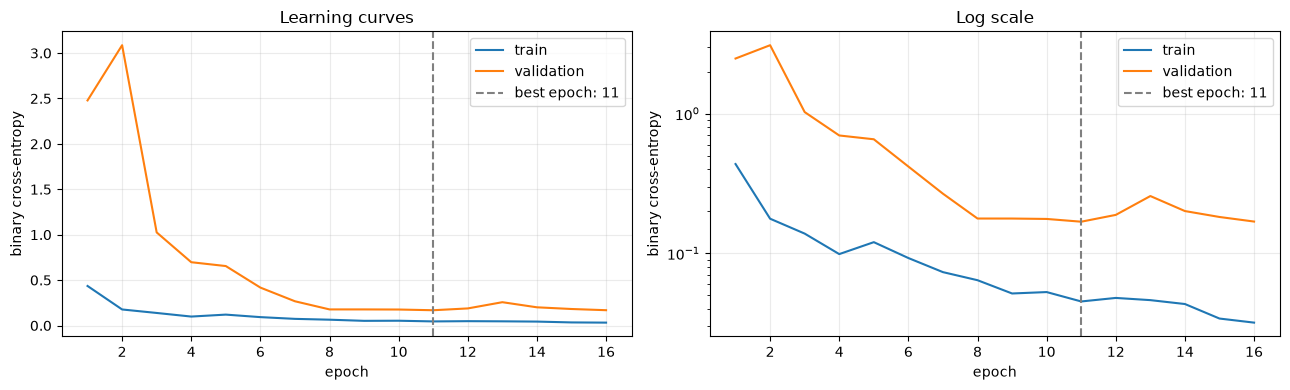

In [6]:
# Learning curves (the log scale shows the small variations)
epochs = np.arange(1, len(history["loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), tight_layout=True)
for a in ax:
    a.plot(epochs, history["loss"], label="train"); a.plot(epochs, history["val_loss"], label="validation")
    a.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch: {best_epoch}")
    a.set_xlabel("epoch"); a.set_ylabel("binary cross-entropy"); a.legend(); a.grid(alpha=0.25)
ax[0].set_title("Learning curves"); ax[1].set_yscale("log"); ax[1].set_title("Log scale")
plt.savefig(FIG_DIR / "A_01_learning_curves.png", dpi=80)
plt.show()

## 4. Threshold chosen on validation
The search compares 51 quantiles of the validation probabilities (0.01 to 0.99) and keeps the best per-image mean F1. Predicted components under `MIN_OBJECT_PX` (4 px, 8-connectivity) are removed, as for every model. The probabilities are used as they are: no smoothing and no per-image z-score.

In [7]:
prob_val = model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)[..., 0]
THRESHOLD, MIN_BLOB, best_f1, _ = pp.select_threshold(gt_val, prob_val, quantiles=THRESHOLD_QUANTILES,
                                                      min_blob_candidates=(MIN_OBJECT_PX,))
masks_val = pp.to_masks(prob_val, THRESHOLD, MIN_BLOB)
free_val = evaluation.threshold_free_scores(gt_val, prob_val)
report_val = evaluation.mask_report(gt_val, masks_val)
print(f"Threshold chosen on validation: {THRESHOLD:.6f} (per-image mean F1 {best_f1:.4f})")
pd.Series(evaluation.summary(free_val, report_val), name="validation").to_frame()

Threshold chosen on validation: 0.482264 (per-image mean F1 0.6950)


,validation
AuPRC (main),0.753624
AUROC,0.927511
AUPRO@0.3,0.825802
FPR95 (lower is better),0.437995
F1 = Dice (per-image mean),0.695027
IoU (per-image mean),0.57529
precision (per-image mean),0.735071
recall (per-image mean),0.792561
F1 (aggregated),0.691341
Boundary IoU (15 px band),0.47599


## 5. Validation examples
Three fixed validation images (first, middle, last), not chosen by their scores. White: correctly detected; red: false alarm; blue: missed.

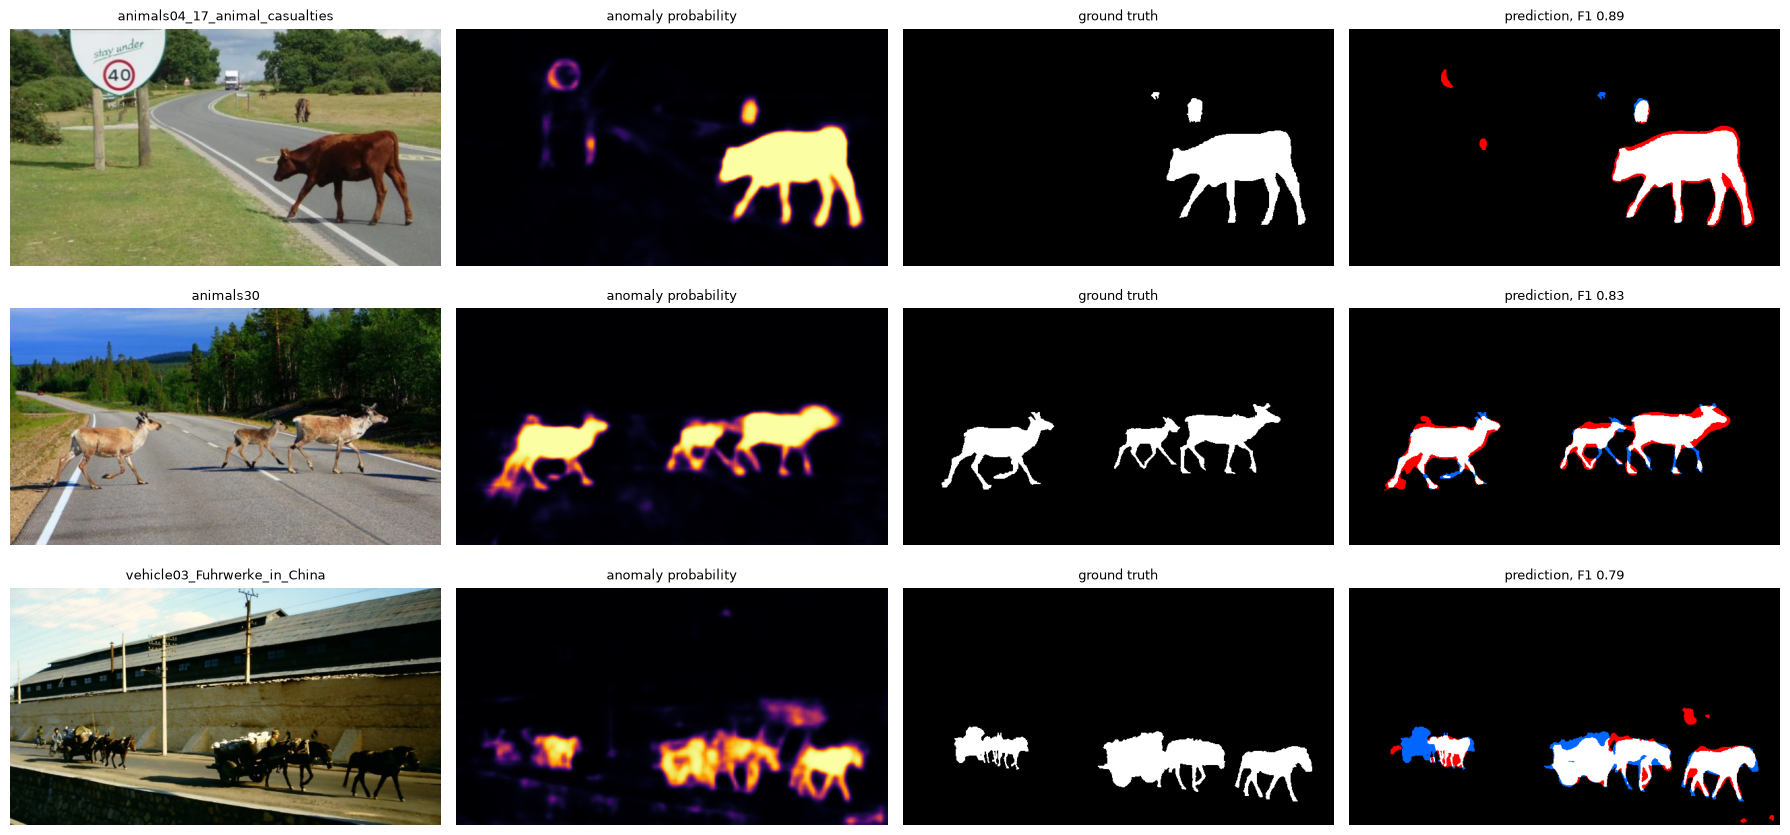

In [8]:
def error_overlay(truth, pred):
    """RGB map: white = TP, red = FP, blue = FN, black = TN."""
    errors = np.zeros((*truth.shape, 3), np.float32)
    errors[truth & pred] = (1, 1, 1); errors[~truth & pred] = (1, 0, 0); errors[truth & ~pred] = (0, 0.4, 1)
    return errors

indices = [0, len(x_val) // 2, len(x_val) - 1]
fig, ax = plt.subplots(len(indices), 4, figsize=(18, 3 * len(indices)), tight_layout=True)
for row, i in enumerate(indices):
    f1 = report_val["pixel"]["per_image"][i]["f1"]
    for col, (panel, title) in enumerate([(x_val[i], val_frames[i][:30]), (prob_val[i], "anomaly probability"),
                                          (gt_val[i], "ground truth"),
                                          (error_overlay(gt_val[i], masks_val[i].astype(bool)), f"prediction, F1 {f1:.2f}")]):
        ax[row, col].imshow(panel, cmap="inferno" if col == 1 else ("gray" if panel.ndim == 2 else None))
        ax[row, col].set_title(title, fontsize=9); ax[row, col].axis("off")
plt.savefig(FIG_DIR / "A_02_validation_examples.png", dpi=60)
plt.show()

In [9]:
# Save the model in the shared format (models/A_deeplabv3plus/)
save_artifact(dp.MODELS_DIR / "A_deeplabv3plus", model, {
    "name": "A_deeplabv3plus", "binome": "A", "title": "DeepLabV3+ (frozen ImageNet ResNet50 encoder)",
    "model_type": "segmentation",
    "input": {"image_size": list(IMG_SIZE), "channels": "RGB", "range": [0, 1]},
    "postprocessing": {"sigma": 0, "per_image_z_score": False, "threshold": THRESHOLD, "min_blob_px": MIN_BLOB},
    "selection": {"split": "val", "checkpoint_rule": "minimum validation loss",
                  "threshold_rule": "best per-image mean F1 over 51 quantiles (0.01-0.99)"},
    "validation": {**free_val, **report_val["pixel"]["per_image_mean"]},
    "training": {"seed": SEED, "batch_size": BATCH_SIZE, "learning_rate": LEARNING_RATE, "loss": "binary_crossentropy",
                 "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "epochs_ran": len(history["loss"]),
                 "best_epoch": best_epoch, "encoder": "ResNet50 ImageNet, frozen", "decoder_channels": DECODER_CHANNELS},
})
print("saved models/A_deeplabv3plus")

saved models/A_deeplabv3plus


## 6. Findings of the modeling phase (validation)
- A frozen ImageNet encoder with a trained ASPP and decoder learns the task from 42 annotated images; the checkpoint and the threshold are fixed on validation before any test image is seen.
- AP and AUROC pool all pixels and use the raw probabilities; F1 / IoU use the thresholded, speckle-filtered masks, with every image weighing the same.
- The validation examples show the typical errors: main regions found, but fine details, contours and the separation of neighbouring objects remain difficult.
- Not claimed here: fine-tuning of the encoder, Boundary IoU, or a multi-class mIoU (the labels are binary).

The test evaluation (with A, B and C side by side) is in [`../5_Evaluation.ipynb`](../5_Evaluation.ipynb), Seg-Grad-CAM and the deletion / insertion check in [`../6_XAI.ipynb`](../6_XAI.ipynb).